<sub>**The Annotated ML Handbook** · Part IV: Visualization · by Mahir Absar Khan</sub>

# Chapter 18: Figures for papers, theses and assignments

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Mahir-606/annotated-ml-handbook/blob/main/notebooks/part-4-visualization/18-viz-export.ipynb) &nbsp; [📚 Contents](../../book/README.md) &nbsp; [🌐 Web edition](https://mahir-606.github.io/annotated-ml-handbook/)

*Run the setup cell first, then read and run the cells from top to bottom. Every code cell is followed by a table explaining what each line does.*

In [1]:
# Repository setup (not part of the book's examples): run this cell first.
import os, sys
from pathlib import Path

# Files the examples create (CSV, models, figures) go into ./outputs next to the notebook.
OUT = Path.cwd() if Path.cwd().name == "outputs" else Path.cwd() / "outputs"
OUT.mkdir(exist_ok=True)
os.chdir(OUT)

# insurance.csv is the practice dataset created in Chapter 11 and reused by later chapters.
# If it is not here yet, copy it from the repository's data/ folder (or download it in Colab).
if not Path("insurance.csv").exists():
    import shutil, urllib.request
    for base in OUT.parents:
        if (base / "data" / "insurance.csv").exists():
            shutil.copy(base / "data" / "insurance.csv", "insurance.csv")
            break
    else:
        try:
            urllib.request.urlretrieve("https://raw.githubusercontent.com/Mahir-606/"
                                       "annotated-ml-handbook/main/data/insurance.csv", "insurance.csv")
        except Exception as e:
            print("Could not fetch insurance.csv; run Chapter 11 first.", e)

# The figure style used in the book.
import matplotlib.pyplot as plt
from cycler import cycler
plt.rcParams.update({
    "figure.figsize": (7.2, 4.0), "figure.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.28, "grid.linewidth": 0.6,
    "axes.prop_cycle": cycler(color=["#1f4fff", "#e0245e", "#0f9b62", "#ff6a00",
                                     "#7b3ff2", "#0091b3", "#d99a00", "#d42a2a"]),
    "axes.titleweight": "bold", "axes.titlesize": 12.5, "axes.titlelocation": "left",
    "font.size": 10.5, "legend.frameon": False, "image.cmap": "viridis",
})

# Plotly: interactive in Jupyter/Colab; tools/run_all.py stores static PNGs so GitHub can show them.
try:
    import plotly.io as pio
    pio.renderers.default = os.environ.get("PLOTLY_RENDERER") or (
        "colab" if "google.colab" in sys.modules else "notebook_connected")
except ImportError:
    pass

A chart that looks fine on screen can be blurry in print, unreadable at column width, or rejected by a journal's submission system. This chapter is a practical guide to getting figures out of Python as PNG, PDF, SVG or TIFF files, at the right size and resolution, and into Word, Google Docs, PowerPoint or LaTeX.

## 18.1 Raster vs vector: which format? · *Beginner*

> **📖 Definitions**
>
> **Raster image**: a grid of coloured pixels (PNG, JPEG, TIFF). It has a fixed resolution and becomes blurry or blocky when enlarged. **Vector image**: a description of shapes, lines and text (PDF, SVG, EPS). It stays perfectly sharp at any size and its text remains selectable.
>
> **DPI (dots per inch)**: how many pixels are printed per inch of paper. A 3.5-inch-wide figure at 300 dpi is 1,050 pixels wide.

| Format | Type | Best for | Avoid for |
|---|---|---|---|
| **PDF** | vector | LaTeX papers and theses, journal submissions, printing | very dense scatter plots (huge files): rasterise the points (see 18.4) |
| **SVG** | vector | editing in Inkscape or Illustrator, Word 365, websites | some older journal systems |
| **EPS** | vector | journals that explicitly ask for it | transparency (EPS doesn't support it) |
| **PNG** | raster, lossless | Word, Google Docs, PowerPoint, websites, photos of plots | enlarging after export |
| **TIFF** | raster, lossless | journals that require TIFF for submission | everyday use (very large files) |
| **JPEG** | raster, lossy | photographs only | charts: compression blurs lines and text |

> **💡 Tip** · **The two-file habit**
>
> Save every final figure twice: a **PDF** (vector, for LaTeX, printing and later editing) and a **300-dpi PNG** (for Word, slides and quick sharing). The function in section 18.6 does both in one call.

## 18.2 Size first, then resolution · *Beginner*

The most common mistake is making a figure at screen size and shrinking it into the paper, which makes the fonts tiny. Instead, **create the figure at its final printed size** and choose font sizes for that size.

| Target | Width | Typical font size |
|---|---|---|
| Journal, single column | 3.3–3.5 in (85–90 mm) | 7–9 pt |
| Journal, double column (full width) | 6.7–7.2 in (170–183 mm) | 7–9 pt |
| A4 thesis or assignment, full text width | about 6.3 in (160 mm) | 9–11 pt |
| Slide (16:9) | 10–13 in | 14–20 pt |
| Poster panel | 10–20 in | 20+ pt |

Always check your journal's author guidelines; the numbers above are common defaults, not rules.

**Create a figure at its final size**

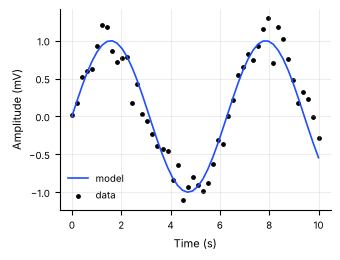

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
rng = np.random.default_rng(0)
plt.rcParams.update({"font.size": 8, "axes.titlesize": 9, "axes.labelsize": 8,
                     "xtick.labelsize": 7, "ytick.labelsize": 7, "legend.fontsize": 7})
x = np.linspace(0, 10, 50)
fig, ax = plt.subplots(figsize=(3.5, 2.6))
ax.plot(x, np.sin(x), label="model", lw=1.2)
ax.scatter(x, np.sin(x) + rng.normal(0, 0.2, 50), s=6, label="data", color="k")
ax.set(xlabel="Time (s)", ylabel="Amplitude (mV)")
ax.legend(frameon=False)
plt.show()

<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>import numpy as np</code></td><td>Arrays.</td></tr>
<tr><td><code>import matplotlib.pyplot as plt</code></td><td>Plotting.</td></tr>
<tr><td><code>from pathlib import Path</code></td><td>File checks.</td></tr>
<tr><td><code>rng = np.random.default_rng(0)</code></td><td>Seeded generator.</td></tr>
<tr><td><code>plt.rcParams.update({&quot;font.size&quot;: 8, &quot;axes.titlesize&quot;: 9, &quot;axes.labelsize&quot;: 8,</code></td><td>Font sizes for print.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&quot;xtick.labelsize&quot;: 7, &quot;ytick.labelsize&quot;: 7, &quot;legend.fontsize&quot;: 7})</code></td><td>Ticks and legend slightly smaller.</td></tr>
<tr><td><code>x = np.linspace(0, 10, 50)</code></td><td>Data.</td></tr>
<tr><td><code>fig, ax = plt.subplots(figsize=(3.5, 2.6))</code></td><td>Width x height in inches, the final printed size.</td></tr>
<tr><td><code>ax.plot(x, np.sin(x), label=&quot;model&quot;, lw=1.2)</code></td><td>Thin lines suit small figures.</td></tr>
<tr><td><code>ax.scatter(x, np.sin(x) + rng.normal(0, 0.2, 50), s=6, label=&quot;data&quot;, color=&quot;k&quot;)</code></td><td>Small markers.</td></tr>
<tr><td><code>ax.set(xlabel=&quot;Time (s)&quot;, ylabel=&quot;Amplitude (mV)&quot;)</code></td><td>Axis labels with units.</td></tr>
<tr><td><code>ax.legend(frameon=False)</code></td><td>Legend without a box.</td></tr>
<tr><td><code>plt.show()</code></td><td>Display.</td></tr>
</table>
</details>

## 18.3 Saving with `savefig`: every option that matters · *Beginner*

**The savefig options explained**

In [3]:
fig, ax = plt.subplots(figsize=(3.5, 2.6))
ax.plot(x, np.cos(x), lw=1.2)
ax.set(xlabel="Time (s)", ylabel="Amplitude (mV)")
fig.savefig("fig_a.png",
            dpi=300,
            bbox_inches="tight",
            pad_inches=0.02,
            facecolor="white",
            transparent=False)
fig.savefig("fig_a.pdf", bbox_inches="tight")
plt.close(fig)
from PIL import Image
with Image.open("fig_a.png") as im:
    w, h = im.size
print(f"PNG: {w} x {h} px  ->  {w / 300:.2f} x {h / 300:.2f} in at 300 dpi")

PNG: 993 x 734 px  ->  3.31 x 2.45 in at 300 dpi


<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>fig, ax = plt.subplots(figsize=(3.5, 2.6))</code></td><td>A figure at final size.</td></tr>
<tr><td><code>ax.plot(x, np.cos(x), lw=1.2)</code></td><td>Any content.</td></tr>
<tr><td><code>ax.set(xlabel=&quot;Time (s)&quot;, ylabel=&quot;Amplitude (mV)&quot;)</code></td><td>Labels.</td></tr>
<tr><td><code>fig.savefig(&quot;fig_a.png&quot;,</code></td><td>The file name; the extension picks the format.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;dpi=300,</code></td><td>Resolution for raster formats (ignored by vector formats for lines and text).</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;bbox_inches=&quot;tight&quot;,</code></td><td>Crop away surrounding white space...</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;pad_inches=0.02,</code></td><td>...but keep a tiny margin.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;facecolor=&quot;white&quot;,</code></td><td>Background colour (avoids a transparent background in dark-mode viewers).</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;transparent=False)</code></td><td>True gives a transparent background, useful for posters on coloured backgrounds.</td></tr>
<tr><td><code>fig.savefig(&quot;fig_a.pdf&quot;, bbox_inches=&quot;tight&quot;)</code></td><td>Vector version.</td></tr>
<tr><td><code>plt.close(fig)</code></td><td>Close it, since we only wanted the files.</td></tr>
<tr><td><code>from PIL import Image</code></td><td>Pillow reads images (installed with Matplotlib).</td></tr>
<tr><td><code>with Image.open(&quot;fig_a.png&quot;) as im:</code></td><td>Open the PNG (the with-block closes the file afterwards).</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;w, h = im.size</code></td><td>Its pixel dimensions.</td></tr>
<tr><td><code>print(f&quot;PNG: {w} x {h} px  -&gt;  {w / 300:.2f} x {h / 300:.2f} in at 300 dpi&quot;)</code></td><td>Pixels / dpi = printed inches (slightly under 3.5 because of the crop).</td></tr>
</table>
</details>

### 18.3.1 Fonts that journals and Word accept · *Intermediate*

**Embed fonts as TrueType in PDF and keep text editable in SVG**

In [4]:
plt.rcParams["pdf.fonttype"] = 42
plt.rcParams["ps.fonttype"] = 42
plt.rcParams["svg.fonttype"] = "none"
plt.rcParams["font.family"] = "DejaVu Sans"
fig, ax = plt.subplots(figsize=(3.5, 2.4))
ax.bar(["A", "B", "C"], [3, 5, 2])
ax.set_ylabel("Count")
fig.savefig("fig_fonts.pdf", bbox_inches="tight")
fig.savefig("fig_fonts.svg", bbox_inches="tight")
plt.close(fig)
print("PDF has Type 3 fonts:", b"/Type3" in Path("fig_fonts.pdf").read_bytes())

PDF has Type 3 fonts: False


<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>plt.rcParams[&quot;pdf.fonttype&quot;] = 42</code></td><td>Embed TrueType (Type 42) fonts: many journals reject Type 3 fonts.</td></tr>
<tr><td><code>plt.rcParams[&quot;ps.fonttype&quot;] = 42</code></td><td>The same for EPS/PS output.</td></tr>
<tr><td><code>plt.rcParams[&quot;svg.fonttype&quot;] = &quot;none&quot;</code></td><td>Keep SVG text as real text (editable) instead of converting it to paths.</td></tr>
<tr><td><code>plt.rcParams[&quot;font.family&quot;] = &quot;DejaVu Sans&quot;</code></td><td>A font that is always available; use &quot;Arial&quot; or &quot;Times New Roman&quot; if installed and required.</td></tr>
<tr><td><code>fig, ax = plt.subplots(figsize=(3.5, 2.4))</code></td><td>New figure.</td></tr>
<tr><td><code>ax.bar([&quot;A&quot;, &quot;B&quot;, &quot;C&quot;], [3, 5, 2])</code></td><td>Content.</td></tr>
<tr><td><code>ax.set_ylabel(&quot;Count&quot;)</code></td><td>Label.</td></tr>
<tr><td><code>fig.savefig(&quot;fig_fonts.pdf&quot;, bbox_inches=&quot;tight&quot;)</code></td><td>Fonts embedded as TrueType.</td></tr>
<tr><td><code>fig.savefig(&quot;fig_fonts.svg&quot;, bbox_inches=&quot;tight&quot;)</code></td><td>Text stays editable.</td></tr>
<tr><td><code>plt.close(fig)</code></td><td>Close.</td></tr>
<tr><td><code>print(&quot;PDF has Type 3 fonts:&quot;, b&quot;/Type3&quot; in Path(&quot;fig_fonts.pdf&quot;).read_bytes())</code></td><td>Check: should print False.</td></tr>
</table>
</details>

> **⚠️ Pitfall** · **Required fonts**
>
> If a journal requires Arial or Helvetica, set `plt.rcParams["font.family"] = "Arial"`. If Matplotlib can't find the font it falls back to another one and warns `findfont: Font family 'Arial' not found`. Install the font on your system, then delete Matplotlib's font cache (the folder shown by `matplotlib.get_cachedir()`) and restart Python.

## 18.4 Huge scatter plots: rasterise the points, keep the text sharp · *Intermediate*

A vector PDF with 100,000 points stores every point separately, which gives huge, slow files. Rasterising only the data layer keeps axes and text as vectors.

**rasterized=True**

In [5]:
big = rng.normal(size=(100_000, 2))
for raster in (False, True):
    fig, ax = plt.subplots(figsize=(3.5, 3))
    ax.scatter(big[:, 0], big[:, 1], s=1, alpha=0.3, rasterized=raster)
    ax.set(xlabel="x", ylabel="y")
    name = f"scatter_raster_{raster}.pdf"
    fig.savefig(name, dpi=300, bbox_inches="tight")
    plt.close(fig)
    print(name, Path(name).stat().st_size // 1024, "KB")

scatter_raster_False.pdf 1448 KB


scatter_raster_True.pdf 110 KB


<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>big = rng.normal(size=(100_000, 2))</code></td><td>100,000 points.</td></tr>
<tr><td><code>for raster in (False, True):</code></td><td>Save twice to compare.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;fig, ax = plt.subplots(figsize=(3.5, 3))</code></td><td>New figure.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;ax.scatter(big[:, 0], big[:, 1], s=1, alpha=0.3, rasterized=raster)</code></td><td>rasterized=True turns only this layer into pixels.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;ax.set(xlabel=&quot;x&quot;, ylabel=&quot;y&quot;)</code></td><td>Labels stay vector text.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;name = f&quot;scatter_raster_{raster}.pdf&quot;</code></td><td>File name records the setting.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;fig.savefig(name, dpi=300, bbox_inches=&quot;tight&quot;)</code></td><td>dpi sets the resolution of the rasterised layer.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;plt.close(fig)</code></td><td>Close.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;print(name, Path(name).stat().st_size // 1024, &quot;KB&quot;)</code></td><td>Compare file sizes.</td></tr>
</table>
</details>

## 18.5 Multi-panel figures with panel letters · *Intermediate*

Journals usually want related plots combined into one figure with panels labelled **a**, **b**, **c**.

**A publication-style two-panel figure**

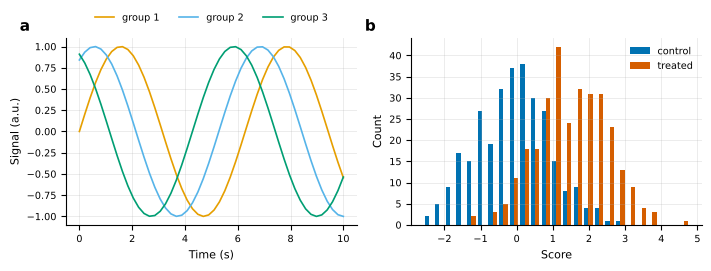

In [6]:
okabe_ito = ["#E69F00", "#56B4E9", "#009E73", "#0072B2", "#D55E00", "#CC79A7"]
fig, axes = plt.subplots(1, 2, figsize=(7, 2.6), layout="constrained")
for i, c in enumerate(okabe_ito[:3]):
    axes[0].plot(x, np.sin(x + i), color=c, lw=1.2, label=f"group {i + 1}")
axes[0].set(xlabel="Time (s)", ylabel="Signal (a.u.)")
axes[0].legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, 1.18))
axes[1].hist([rng.normal(m, 1, 300) for m in (0, 1.5)], bins=25, color=okabe_ito[3:5],
             label=["control", "treated"])
axes[1].set(xlabel="Score", ylabel="Count")
axes[1].legend(frameon=False)
for ax, letter in zip(axes, "ab"):
    ax.text(-0.16, 1.02, letter, transform=ax.transAxes, fontsize=11, fontweight="bold", va="bottom")
fig.savefig("figure2.pdf"); fig.savefig("figure2.png", dpi=300)
plt.show()

<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>okabe_ito = [&quot;#E69F00&quot;, &quot;#56B4E9&quot;, &quot;#009E73&quot;, &quot;#0072B2&quot;, &quot;#D55E00&quot;, &quot;#CC79A7&quot;]</code></td><td>A widely used colour-blind-safe palette.</td></tr>
<tr><td><code>fig, axes = plt.subplots(1, 2, figsize=(7, 2.6), layout=&quot;constrained&quot;)</code></td><td>Full width; constrained layout avoids overlaps.</td></tr>
<tr><td><code>for i, c in enumerate(okabe_ito[:3]):</code></td><td>Three groups.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;axes[0].plot(x, np.sin(x + i), color=c, lw=1.2, label=f&quot;group {i + 1}&quot;)</code></td><td>One line each.</td></tr>
<tr><td><code>axes[0].set(xlabel=&quot;Time (s)&quot;, ylabel=&quot;Signal (a.u.)&quot;)</code></td><td>a.u. = arbitrary units.</td></tr>
<tr><td><code>axes[0].legend(frameon=False, ncol=3, loc=&quot;upper center&quot;, bbox_to_anchor=(0.5, 1.18))</code></td><td>Legend in one row above the panel.</td></tr>
<tr><td><code>axes[1].hist([rng.normal(m, 1, 300) for m in (0, 1.5)], bins=25, color=okabe_ito[3:5],</code></td><td>Two histograms side by side.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;label=[&quot;control&quot;, &quot;treated&quot;])</code></td><td>Labels.</td></tr>
<tr><td><code>axes[1].set(xlabel=&quot;Score&quot;, ylabel=&quot;Count&quot;)</code></td><td>Labels.</td></tr>
<tr><td><code>axes[1].legend(frameon=False)</code></td><td>Legend.</td></tr>
<tr><td><code>for ax, letter in zip(axes, &quot;ab&quot;):</code></td><td>Pair each panel with a letter.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;ax.text(-0.16, 1.02, letter, transform=ax.transAxes, fontsize=11, fontweight=&quot;bold&quot;, va=&quot;bottom&quot;)</code></td><td>Placed in axes coordinates, top-left outside the plot.</td></tr>
<tr><td><code>fig.savefig(&quot;figure2.pdf&quot;); fig.savefig(&quot;figure2.png&quot;, dpi=300)</code></td><td>Both formats.</td></tr>
<tr><td><code>plt.show()</code></td><td>Display.</td></tr>
</table>
</details>

## 18.6 One function to export everything · *Beginner*

**save_figure(): consistent export for a whole project**

In [7]:
def save_figure(fig, name, folder="figures", formats=("pdf", "png"), dpi=300):
    """Save `fig` in several formats into `folder` and return the file paths."""
    out = Path(folder)
    out.mkdir(parents=True, exist_ok=True)
    paths = []
    for fmt in formats:
        p = out / f"{name}.{fmt}"
        fig.savefig(p, dpi=dpi, bbox_inches="tight", facecolor="white")
        paths.append(p)
    return paths

fig, ax = plt.subplots(figsize=(3.5, 2.4))
ax.plot([1, 2, 3], [2, 4, 3], marker="o")
for p in save_figure(fig, "fig3", formats=("pdf", "png", "svg", "tiff")):
    print(p, p.stat().st_size // 1024, "KB")
plt.close(fig)

figures/fig3.pdf 7 KB
figures/fig3.png 47 KB
figures/fig3.svg 13 KB
figures/fig3.tiff 2538 KB


<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;out = Path(folder)</code></td><td>The output folder as a Path.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;out.mkdir(parents=True, exist_ok=True)</code></td><td>Create it if needed.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;paths = []</code></td><td>Collect the saved paths.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;for fmt in formats:</code></td><td>One file per format.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;p = out / f&quot;{name}.{fmt}&quot;</code></td><td>e.g. figures/fig3.pdf</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;fig.savefig(p, dpi=dpi, bbox_inches=&quot;tight&quot;, facecolor=&quot;white&quot;)</code></td><td>The standard options.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;paths.append(p)</code></td><td>Remember it.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;return paths</code></td><td>Hand the list back.</td></tr>
<tr><td><code>fig, ax = plt.subplots(figsize=(3.5, 2.4))</code></td><td>Any figure.</td></tr>
<tr><td><code>ax.plot([1, 2, 3], [2, 4, 3], marker=&quot;o&quot;)</code></td><td>Content.</td></tr>
<tr><td><code>for p in save_figure(fig, &quot;fig3&quot;, formats=(&quot;pdf&quot;, &quot;png&quot;, &quot;svg&quot;, &quot;tiff&quot;)):</code></td><td>TIFF too, for journals that require it.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;print(p, p.stat().st_size // 1024, &quot;KB&quot;)</code></td><td>Report each file.</td></tr>
<tr><td><code>plt.close(fig)</code></td><td>Close.</td></tr>
</table>
</details>

## 18.7 Exporting Seaborn and Plotly figures · *Beginner*

| Library | Code |
|---|---|
| Matplotlib | `fig.savefig("f.pdf")`, `fig.savefig("f.png", dpi=300)` |
| Seaborn axes-level (`histplot`, `boxplot`, …) | draw with `ax=ax`, then `fig.savefig(...)` |
| Seaborn figure-level (`relplot`, `displot`, `catplot`, `pairplot`, `jointplot`) | `g = sns.relplot(...)`, then `g.savefig("f.pdf")` |
| Plotly | `fig.write_image("f.png", width=700, height=450, scale=3)`, `fig.write_image("f.pdf")`, `fig.write_html("f.html")` |
| pandas `.plot()` | `ax = df.plot(...)`, then `ax.figure.savefig("f.png", dpi=300)` |

For Plotly, the pixel size of a PNG is `width × scale`. For a 7-inch figure at 300 dpi you need 2,100 pixels: `width=700, scale=3`.

## 18.8 Putting figures into documents · *Beginner*

| Destination | Use | How |
|---|---|---|
| **Microsoft Word** | PNG at 300 dpi (any version), or SVG (Word 365) | Insert → Pictures → This Device. Right-click → Size and Position: set the width and keep "Lock aspect ratio" ticked. Don't stretch a small image larger. |
| **Google Docs** | PNG at 300 dpi | Insert → Image → Upload from computer. |
| **PowerPoint / Keynote** | SVG (365) or high-resolution PNG | Insert → Pictures. Make the figure at slide size with large fonts. |
| **LaTeX / Overleaf** | PDF | Upload the PDF, then use the code below. |
| **Journal submission** | what the guidelines say (often PDF/EPS for plots, TIFF for images) | Name files `Figure1.pdf`, `Figure2.pdf`, and keep the code that made them. |

```text
% LaTeX: include a vector PDF figure at full text width
\begin{figure}[t]
  \centering
  \includegraphics[width=\linewidth]{figures/figure2.pdf}
  \caption{(a) Signal over time for three groups. (b) Score distributions;
           treated participants score higher.}
  \label{fig:results}
\end{figure}
```

## 18.9 Writing a good figure caption · *Beginner*

A caption should let a reader understand the figure without reading the main text:

1. **Title sentence** stating what is shown, or better, the finding ("Treated participants scored higher than controls").
2. **What each panel shows** (a, b, c).
3. **What the marks mean**: error bars (SD, SEM or 95% CI?), shaded bands, dot sizes, colours.
4. **Sample sizes** (n per group) and, if relevant, the statistical test.

## 18.10 Colour and accessibility · *Intermediate*

**Check a figure in grayscale**

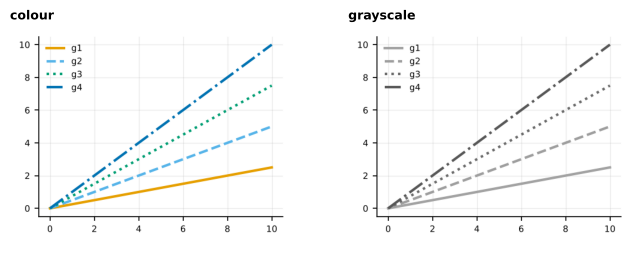

In [8]:
fig, ax = plt.subplots(figsize=(3.5, 2.6))
for i, c in enumerate(okabe_ito[:4]):
    ax.plot(x, x * (i + 1) / 4, color=c, lw=2, ls=["-", "--", ":", "-."][i], label=f"g{i + 1}")
ax.legend(frameon=False)
fig.savefig("colour_check.png", dpi=150, bbox_inches="tight")
plt.close(fig)
img = Image.open("colour_check.png")
fig, axes = plt.subplots(1, 2, figsize=(8, 3))
axes[0].imshow(img); axes[0].set_title("colour")
axes[1].imshow(img.convert("L"), cmap="gray"); axes[1].set_title("grayscale")
for a in axes: a.axis("off")
plt.show()

<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>fig, ax = plt.subplots(figsize=(3.5, 2.6))</code></td><td>A figure using the Okabe-Ito palette.</td></tr>
<tr><td><code>for i, c in enumerate(okabe_ito[:4]):</code></td><td>Four lines.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;ax.plot(x, x * (i + 1) / 4, color=c, lw=2, ls=[&quot;-&quot;, &quot;--&quot;, &quot;:&quot;, &quot;-.&quot;][i], label=f&quot;g{i + 1}&quot;)</code></td><td>Colour AND line style: redundant encoding.</td></tr>
<tr><td><code>ax.legend(frameon=False)</code></td><td>Legend.</td></tr>
<tr><td><code>fig.savefig(&quot;colour_check.png&quot;, dpi=150, bbox_inches=&quot;tight&quot;)</code></td><td>Save it.</td></tr>
<tr><td><code>plt.close(fig)</code></td><td>Close.</td></tr>
<tr><td><code>img = Image.open(&quot;colour_check.png&quot;)</code></td><td>Reload the saved image.</td></tr>
<tr><td><code>fig, axes = plt.subplots(1, 2, figsize=(8, 3))</code></td><td>Side-by-side comparison.</td></tr>
<tr><td><code>axes[0].imshow(img); axes[0].set_title(&quot;colour&quot;)</code></td><td>Original.</td></tr>
<tr><td><code>axes[1].imshow(img.convert(&quot;L&quot;), cmap=&quot;gray&quot;); axes[1].set_title(&quot;grayscale&quot;)</code></td><td>convert(&quot;L&quot;) = grayscale.</td></tr>
<tr><td><code>for a in axes: a.axis(&quot;off&quot;)</code></td><td>Hide axes around the pictures.</td></tr>
<tr><td><code>plt.show()</code></td><td>Display.</td></tr>
</table>
</details>

## 18.11 Final-figure checklist · *Beginner*

- [ ] Made at the final printed size, with fonts of at least 7 pt at that size.
- [ ] Axes labelled, with units; tick labels readable.
- [ ] Colour-blind-safe palette, plus line styles or markers so it still works in grayscale.
- [ ] Error bars and bands defined in the caption (SD, SEM or 95% CI), with n stated.
- [ ] Saved as PDF (vector) and 300-dpi PNG; TIFF or EPS if the journal asks.
- [ ] Fonts embedded (`pdf.fonttype = 42`); dense scatter layers rasterised.
- [ ] Panel letters on multi-panel figures; consistent styling across all figures.
- [ ] The code that generated it saved in your project, so it can be regenerated.

> **✍️ Try it yourself**
>
> 1. Rebuild one figure from [Chapter 15](15-viz-mpl-gallery.ipynb) at 3.5 inches wide with 8-pt fonts and save it with `save_figure()`.
> 2. Make a 7 x 3 inch, three-panel figure (a, b, c) from the insurance data and export it as PDF and PNG.
> 3. Open your PNG in an image viewer and confirm its pixel width equals inches × dpi.
>
> *Worked solutions:* [solutions-parts-1-4.ipynb](../../solutions/solutions-parts-1-4.ipynb), section *Chapter 18*.

---

⬅️ [Chapter 17: Interactive charts with Plotly](17-viz-plotly.ipynb) · [📚 Contents](../../book/README.md) · [Chapter 19: Machine-learning concepts and the scikit-learn API](../part-5-scikit-learn/19-sklearn-concepts.ipynb) ➡️